### Imports

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay


from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

base_path = Path("data")
PATH_CARAC = base_path / "Caracteristiques_2024.csv"
PATH_LIEUX = base_path / "Lieux_2024.csv"
PATH_USAGERS = base_path / "Usagers_2024.csv"
PATH_VEHICLE = base_path / "vehicules-2024.csv"
PATH_COMMUNES = base_path / "Communes-france-2024.csv"  # pas tout de suite
PATH_BPE = base_path / "BPE-2024.csv"  # pas tout de suite

carac = pd.read_csv(
    PATH_CARAC,
    sep=";",
    dtype={"Num_Acc": "int64"},
    skipinitialspace=True,
    low_memory=False,
)
lieux = pd.read_csv(
    PATH_LIEUX,
    sep=";",
    dtype={"Num_Acc": "int64"},
    skipinitialspace=True,
    low_memory=False,
)
usagers = pd.read_csv(
    PATH_USAGERS,
    sep=";",
    dtype={"Num_Acc": "int64"},
    skipinitialspace=True,
    low_memory=False,
)
vehicule = pd.read_csv(
    PATH_VEHICLE,
    sep=";",
    dtype={"Num_Acc": "int64"},
    skipinitialspace=True,
    low_memory=False,
)

#carac (54402, 15), lieux (70248, 18), usagers (125187, 16), vehicule (92678, 11) 

### Step01 : join Carateristiques et Lieux en aggregant avec Num_Acc 

In [2]:
# Lieux n'est pas one-to-one avec Carac : on agrège par Num_Acc avant merge
agg_spec = {"n_lieux": ("Num_Acc", "size")} #n_lieux : nombre de lignes dans lieux pour chaque accident(Num_Acc)
for c in lieux.columns: #pour chaque colonne de lieux sil y'a plusieurs lignes pour le meme accident on garde la premiere ligne ( la premiere valeur rencontrée)
    if c != "Num_Acc":
        agg_spec[c] = (c, "first")


lieux_1 = lieux.groupby("Num_Acc", as_index=False, sort=False).agg(**agg_spec)

# on joint carac (1 ligne/accident) avec lieux_1 (1 ligne/accident) sur Num_Acc
acc = carac.merge(lieux_1, on="Num_Acc", how="left", validate="one_to_one")

out_dir = base_path / "intermediate"
out_dir.mkdir(parents=True, exist_ok=True)
out_path = out_dir / "step01_accidents_carac_lieux.csv"
acc.to_csv(out_path, sep=";", index=False)
acc.head()

,Num_Acc,jour,mois,an,hrmn,lum,dep,com,agg,int,...,prof,pr,pr1,plan,lartpc,larrout,surf,infra,situ,vma
0,202400000001,25,3,2024,07:40,2,70,70285,1,1,...,1,1,260,2,None,7,1,0,1,90
1,202400000002,20,3,2024,15:05,1,21,21054,2,3,...,1,-1,-1,1,None,-1,9,0,1,30
2,202400000003,22,3,2024,19:30,2,15,15012,1,1,...,1,-1,-1,1,None,-1,1,0,3,50
3,202400000004,24,3,2024,17:50,1,14,14118,2,3,...,1,-1,-1,1,None,-1,1,9,1,50
4,202400000005,25,3,2024,19:35,5,13,13106,1,3,...,1,1,0,1,None,17,2,0,1,50


Le fichier lieux n’étant pas en relation un-à-un avec le fichier carac, plusieurs lignes pouvant correspondre à un même accident identifié par Num_Acc, une étape d’agrégation est nécessaire avant la fusion. Cette agrégation est réalisée au niveau de l’accident afin de garantir une seule ligne par Num_Acc. Pour chaque accident, le nombre de lignes présentes dans le fichier lieux est calculé et stocké dans une variable n_lieux, ce qui permet de conserver l’information sur la multiplicité éventuelle des localisations associées à un même accident. Pour les autres variables du fichier lieux, la première valeur rencontrée est conservée, ce choix étant justifié par la volonté de disposer d’une représentation unique et cohérente de la localisation principale de l’accident, tout en évitant une explosion du nombre de lignes ou une complexification excessive du modèle. Le jeu de données ainsi agrégé, contenant désormais une seule ligne par accident, est ensuite fusionné avec le fichier carac par une jointure gauche sur Num_Acc, en imposant une relation de type one-to-one afin de garantir l’intégrité structurelle des données. Le résultat correspond à un jeu de données intermédiaire au niveau accident, prêt à être enrichi par d’autres tables et à être utilisé dans les étapes suivantes de l’analyse.

### Step02 : join Vehicules et Usagers sur Num_Acc + id_vehicule + num_veh

In [3]:
# Nettoyage des identifiants vehicule/usager (espaces insécables) avant la jointure

def clean_id(series):
    return (
        series.astype(str)
        .str.replace(r"\s+", "", regex=True)
        .str.replace("\ufeff", "", regex=False)
        .str.strip()
    )

vehicule_clean = vehicule.copy()
usagers_clean = usagers.copy()

for df in (vehicule_clean, usagers_clean):
    df["id_vehicule"] = clean_id(df["id_vehicule"])
    df["num_veh"] = clean_id(df["num_veh"])
    df["Num_Acc"] = df["Num_Acc"].astype("int64")

# id_usager peut contenir des espaces insécables, on harmonise aussi
usagers_clean["id_usager"] = clean_id(usagers_clean["id_usager"])

# On supprime d'éventuels doublons clés avant la jointure
vehicule_clean = vehicule_clean.drop_duplicates(subset=["Num_Acc", "id_vehicule", "num_veh"])
usagers_clean = usagers_clean.drop_duplicates(subset=["Num_Acc", "id_vehicule", "num_veh", "id_usager"])

usagers_vehicules = usagers_clean.merge(
    vehicule_clean,
    on=["Num_Acc", "id_vehicule", "num_veh"],
    how="left",
    validate="many_to_one",
    suffixes=("_usager", "_vehicule"),
)

out_dir = base_path / "intermediate"
out_dir.mkdir(parents=True, exist_ok=True)
path_uv = out_dir / "step02_usagers_vehicules.csv"
usagers_vehicules.to_csv(path_uv, sep=";", index=False)

usagers_vehicules.head()


,Num_Acc,id_usager,id_vehicule,num_veh,place,catu,grav,sexe,an_nais,trajet,...,actp,etatp,senc,catv,obs,obsm,choc,manv,motor,occutc
0,202400000001,203988581,155781758,A01,1,1,3,1,2003.0,2,...,-1,-1,1,7,0,2,1,13,1,NaN
1,202400000001,203988582,155781759,B01,1,1,1,1,1997.0,4,...,-1,-1,2,14,0,2,2,21,1,NaN
2,202400000002,203988579,155781757,A01,10,3,3,2,1927.0,5,...,3,1,1,10,0,1,3,15,1,NaN
3,202400000002,203988580,155781757,A01,1,1,1,1,1987.0,4,...,3,1,1,10,0,1,3,15,1,NaN
4,202400000003,203988574,155781756,A01,2,2,4,2,2007.0,5,...,-1,-1,3,3,9,1,1,1,1,NaN


Le document ONISR précise que `Num_Acc` relie les 4 tables et que `id_vehicule` relie véhicules et occupants. Cette étape nettoie ces identifiants (espaces insécables, BOM) puis joint les usagers à leur véhicule avec `validate='many_to_one'` pour garantir qu'un véhicule n'est associé qu'à une seule ligne côté véhicule. Le résultat reste au niveau usager et est sauvegardé dans `data/intermediate/step02_usagers_vehicules.csv`.


### Step03 : ajouter Caractéristiques + Lieux agrégé au niveau usager

In [4]:
acc_path = base_path / "intermediate" / "step01_accidents_carac_lieux.csv"
uv_path = base_path / "intermediate" / "step02_usagers_vehicules.csv"

# recharge les intermédiaires si nécessaire
if "acc" not in globals():
    acc = pd.read_csv(acc_path, sep=";", dtype={"Num_Acc": "int64"})
if "usagers_vehicules" not in globals():
    usagers_vehicules = pd.read_csv(
        uv_path,
        sep=";",
        dtype={"Num_Acc": "int64", "id_vehicule": str, "num_veh": str},
    )

usagers_vehicules_acc = usagers_vehicules.merge(
    acc,
    on="Num_Acc",
    how="left",
    validate="many_to_one",
)

out_dir = base_path / "intermediate"
out_dir.mkdir(parents=True, exist_ok=True)
path_uv_acc = out_dir / "step03_usagers_vehicules_acc.csv"
usagers_vehicules_acc.to_csv(path_uv_acc, sep=";", index=False)

usagers_vehicules_acc.head()


,Num_Acc,id_usager,id_vehicule,num_veh,place,catu,grav,sexe,an_nais,trajet,...,prof,pr,pr1,plan,lartpc,larrout,surf,infra,situ,vma
0,202400000001,203988581,155781758,A01,1,1,3,1,2003.0,2,...,1,1,260,2,None,7,1,0,1,90
1,202400000001,203988582,155781759,B01,1,1,1,1,1997.0,4,...,1,1,260,2,None,7,1,0,1,90
2,202400000002,203988579,155781757,A01,10,3,3,2,1927.0,5,...,1,-1,-1,1,None,-1,9,0,1,30
3,202400000002,203988580,155781757,A01,1,1,1,1,1987.0,4,...,1,-1,-1,1,None,-1,9,0,1,30
4,202400000003,203988574,155781756,A01,2,2,4,2,2007.0,5,...,1,-1,-1,1,None,-1,1,0,3,50


Cette étape ajoute les informations accident (Caractéristiques + Lieux agrégé) à chaque usager par `Num_Acc`, toujours avec `validate='many_to_one'` pour rester en 1 ligne par usager. Le fichier complet est exporté dans `data/intermediate/step03_usagers_vehicules_acc.csv` et constitue la base d'entraînement (gravité dans `usagers_vehicules_acc.grav`).


### Step04 : agrégation au niveau accident (features agrégées, pas de cible)


In [5]:
uv_acc_path = base_path / "intermediate" / "step03_usagers_vehicules_acc.csv"
uv_acc = pd.read_csv(uv_acc_path, sep=";", dtype={"Num_Acc": "int64"})

# grav est fournie au niveau usager : harmonisation en numérique
uv_acc["grav"] = pd.to_numeric(uv_acc["grav"], errors="coerce")

agg_usagers = uv_acc.groupby("Num_Acc").agg(
    n_usagers=("id_usager", "size"),
    n_vehicules=("id_vehicule", "nunique"),
    n_grav1=("grav", lambda s: (s == 1).sum()),
    n_grav2=("grav", lambda s: (s == 2).sum()),
    n_grav3=("grav", lambda s: (s == 3).sum()),
    n_grav4=("grav", lambda s: (s == 4).sum()),
)

# table accident 1 ligne/Num_Acc (Carac + Lieux + vars vehic/usager non agrégées)
accidents = (
    uv_acc.drop_duplicates(subset=["Num_Acc"])
    .set_index("Num_Acc")
    .drop(columns=["id_usager", "id_vehicule", "num_veh", "grav"])
)

accidents_agg = accidents.join(agg_usagers, how="left").reset_index()

out_path = base_path / "intermediate" / "step04_accidents_agg.csv"
accidents_agg.to_csv(out_path, sep=";", decimal=',', index=False)

accidents_agg[["Num_Acc", "n_usagers", "n_vehicules", "n_grav2", "n_grav3"]].head()


/tmp/ipykernel_429843/3022151428.py:2: DtypeWarning: Columns (50) have mixed types. Specify dtype option on import or set low_memory=False.
  uv_acc = pd.read_csv(uv_acc_path, sep=";", dtype={"Num_Acc": "int64"})


,Num_Acc,n_usagers,n_vehicules,n_grav2,n_grav3
0,202400000001,2,2,0,1
1,202400000002,2,1,0,1
2,202400000003,5,1,0,1
3,202400000004,1,1,0,0
4,202400000005,4,4,0,0


On agrège au niveau accident (`Num_Acc`) pour obtenir une table finale 1 ligne/accident sans générer la cible. 
"
    "Les features ajoutées : nombres d'usagers, de véhicules et répartition par gravité (grav1 à grav4). 
"
    "Le résultat est sauvegardé dans `data/intermediate/step04_accidents_agg.csv` et servira de base d'entraînement, la construction de la cible pourra être faite ultérieurement.


### Step05 : agrégat BPE par commune + jointure sur les accidents


In [6]:

# Step05 : agrégat BPE par commune + jointure sur step04_accidents_agg
bpe_path = base_path / "BPE-2024.csv"
bpe = pd.read_csv(bpe_path, sep=";", dtype={"DEPCOM": str}, low_memory=False)

# agrégation au niveau commune pour éviter les doublons lors du merge
num_cols = [
    "NB_PDC",
    "NB_PDC_PA",
    "NB_PDC_ACCELEREE",
    "NB_PDC_LENTE",
    "NB_PDC_RAPIDE",
    "NB_PDC_ULTRARAPIDE",
]
num_cols = [c for c in num_cols if c in bpe.columns]

context_cols = [
    "DENS3",
    "DENS7",
    "UU2020",
    "AAV2020",
    "BV2022",
    "QP2024",
    "QVA",
    "ZUS",
]
context_cols = [c for c in context_cols if c in bpe.columns]

def mode_or_na(s):
    m = s.mode(dropna=True)
    return m.iloc[0] if not m.empty else pd.NA

agg_spec = {"bpe_total_eq": ("DEPCOM", "size")}
agg_spec.update({c: (c, "sum") for c in num_cols})
agg_spec.update({c: (c, mode_or_na) for c in context_cols})

bpe_agg = bpe.groupby("DEPCOM").agg(**agg_spec).reset_index()

acc_path = base_path / "intermediate" / "step04_accidents_agg.csv"
acc = pd.read_csv(acc_path, sep=";", dtype={"com": str}, decimal=",")
acc["DEPCOM"] = acc["com"].str.zfill(5)

acc_bpe = acc.merge(
    bpe_agg,
    on="DEPCOM",
    how="left",
    validate="many_to_one",
)

out_path = base_path / "intermediate" / "step05_accidents_with_bpe.csv"
acc_bpe.to_csv(out_path, sep=";", index=False)

# contrôle rapide du taux de match
print(acc["DEPCOM"].isin(bpe_agg["DEPCOM"]).value_counts(normalize=True))
acc_bpe.head()





/tmp/ipykernel_429843/3891719426.py:39: DtypeWarning: Columns (46) have mixed types. Specify dtype option on import or set low_memory=False.
  acc = pd.read_csv(acc_path, sep=";", dtype={"com": str}, decimal=",")


DEPCOM
True     0.990699
False    0.009301
Name: proportion, dtype: float64


,Num_Acc,place,catu,sexe,an_nais,trajet,secu1,secu2,secu3,locp,...,NB_PDC_RAPIDE,NB_PDC_ULTRARAPIDE,DENS3,DENS7,UU2020,AAV2020,BV2022,QP2024,QVA,ZUS
0,202400000001,1,1,1,2003.0,2,1,-1,-1,-1,...,1.0,3.0,2.0,2.0,70301,061,70285,HZ,CSZ,HZ
1,202400000002,10,3,2,1927.0,5,0,-1,-1,3,...,19.0,38.0,2.0,2.0,21401,174,21054,CSZ,CSZ,CSZ
2,202400000003,2,2,2,2007.0,5,8,0,-1,-1,...,0.0,0.0,2.0,4.0,15401,123,15014,CSZ,CSZ,CSZ
3,202400000004,1,1,1,1963.0,5,2,6,-1,0,...,2.0,5.0,1.0,1.0,14701,024,14118,HZ,HZ,HZ
4,202400000005,1,1,1,1981.0,0,8,0,-1,-1,...,0.0,0.0,1.0,1.0,00759,003,13055,HZ,CSZ,HZ


Cette étape enrichit la table accident (1 ligne/accident) avec des informations issues du BPE 2024 :
- agrégation par commune (`DEPCOM`) pour éviter les doublons côté BPE (somme des bornes de recharge, total équipements, indicateurs de densité/urbain/social pris au mode).
- construction de la clé commune depuis `com` (carac) via `zfill(5)`, puis jointure gauche `accidents x bpe_agg` en `many_to_one` pour conserver toutes les lignes accident.
Le résultat est sauvegardé dans `data/intermediate/step05_accidents_with_bpe.csv` et reste à 1 ligne par accident, prêt à être utilisé pour l’entraînement.


### Step06 : ajout des features Communes (population, densité, altitude, zone)


In [7]:
# Step06 : join Communes 2024 (features territoriales) sur les accidents enrichis BPE
comm_path = base_path / "Communes-france-2024.csv"
communes = pd.read_csv(comm_path, dtype={"code_insee": str}, low_memory=False)

# sélection des colonnes utiles et renommage clair
cols_keep = [
    "code_insee",
    "population",
    "superficie_km2",
    "densite",
    "altitude_moyenne",
    "altitude_minimale",
    "altitude_maximale",
    "reg_code",
    "reg_nom",
    "dep_code",
    "dep_nom",
    "typecom",
    "typecom_texte",
    "zone_emploi",
    "grille_densite",
]
cols_keep = [c for c in cols_keep if c in communes.columns]
comm_feat = communes[cols_keep].copy()
comm_feat = comm_feat.rename(columns={
    "code_insee": "DEPCOM",
    "population": "comm_population",
    "superficie_km2": "comm_superficie_km2",
    "densite": "comm_densite",
    "altitude_moyenne": "comm_alt_moyenne",
    "altitude_minimale": "comm_alt_min",
    "altitude_maximale": "comm_alt_max",
    "reg_code": "comm_reg_code",
    "reg_nom": "comm_reg_nom",
    "dep_code": "comm_dep_code",
    "dep_nom": "comm_dep_nom",
    "typecom": "comm_type",
    "typecom_texte": "comm_type_txt",
    "zone_emploi": "comm_zone_emploi",
    "grille_densite": "comm_grille_densite",
})

acc_path = base_path / "intermediate" / "step05_accidents_with_bpe.csv"
acc = pd.read_csv(acc_path, sep=";", dtype={"DEPCOM": str})

acc_comm = acc.merge(
    comm_feat,
    on="DEPCOM",
    how="left",
    validate="many_to_one",
)

out_path = base_path / "intermediate" / "step06_accidents_with_bpe_communes.csv"
acc_comm.to_csv(out_path, sep=";", index=False)

# taux de match des communes
print(acc["DEPCOM"].isin(comm_feat["DEPCOM"]).value_counts(normalize=True))
acc_comm.head()


/tmp/ipykernel_429843/38204740.py:44: DtypeWarning: Columns (46) have mixed types. Specify dtype option on import or set low_memory=False.
  acc = pd.read_csv(acc_path, sep=";", dtype={"DEPCOM": str})


DEPCOM
True     0.990938
False    0.009062
Name: proportion, dtype: float64


,Num_Acc,place,catu,sexe,an_nais,trajet,secu1,secu2,secu3,locp,...,comm_alt_min,comm_alt_max,comm_reg_code,comm_reg_nom,comm_dep_code,comm_dep_nom,comm_type,comm_type_txt,comm_zone_emploi,comm_grille_densite
0,202400000001,1,1,1,2003.0,2,1,-1,-1,-1,...,0.0,0.0,27.0,Bourgogne-Franche-Comté,70,Haute-Saône,COM,commune,2705.0,Centres urbains intermédiaires
1,202400000002,10,3,2,1927.0,5,0,-1,-1,3,...,193.0,407.0,27.0,Bourgogne-Franche-Comté,21,Côte-d'Or,COM,commune,2704.0,Centres urbains intermédiaires
2,202400000003,2,2,2,2007.0,5,8,0,-1,-1,...,566.0,844.0,84.0,Auvergne-Rhône-Alpes,15,Cantal,COM,commune,8403.0,Ceintures urbaines
3,202400000004,1,1,1,1963.0,5,2,6,-1,0,...,2.0,73.0,28.0,Normandie,14,Calvados,COM,commune,2804.0,Grands centres urbains
4,202400000005,1,1,1,1981.0,0,8,0,-1,-1,...,140.0,580.0,93.0,Provence-Alpes-Côte d'Azur,13,Bouches-du-Rhône,COM,commune,9312.0,Grands centres urbains


Cette étape ajoute des features territoriales (population, densité, superficie, altitudes, zone d’emploi, type de commune, codes/labels région et département) issues de `Communes-france-2024.csv`. La clé `DEPCOM` (déjà présente dans le dataset enrichi BPE) est utilisée en jointure gauche many-to-one pour conserver 1 ligne par accident. Le résultat est enregistré dans `data/intermediate/step06_accidents_with_bpe_communes.csv`.


In [8]:

# Step07 : analyse pour guider la sélection de features
final_path = base_path / 'intermediate' / 'step06_accidents_with_bpe_communes.csv'
df = pd.read_csv(final_path, sep=';', low_memory=False)

print('=== Shape ===')
print(df.shape)

if 'Y' in df.columns:
    print('\n=== Distribution de Y ===')
    print(df['Y'].value_counts(dropna=False))
    print(df['Y'].value_counts(dropna=False, normalize=True))

print('\n=== Taux de manquants (toutes colonnes) ===')
missing = df.isna().mean().sort_values(ascending=False)
print(missing)

print('\n=== Colonnes quasi constantes (nunique <= 1) ===')
const_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
print(const_cols)

print('\n=== Cardinalité des colonnes catégorielles (toutes) ===')
cat_cols = df.select_dtypes(include='object').columns
card = df[cat_cols].nunique(dropna=False).sort_values(ascending=False)
print(card)

print('\n=== Stats pour quelques numériques clés ===')
num_cols = df.select_dtypes(include='number').columns
sample_num = [c for c in ['n_usagers','n_vehicules','n_grav1','n_grav2','n_grav3','comm_population','comm_densite','bpe_total_eq','NB_PDC'] if c in num_cols]
if sample_num:
    print(df[sample_num].describe(percentiles=[0.1, 0.5, 0.9]).T)
else:
    print('Aucune colonne numérique sélectionnée')

if 'Y' in df.columns:
    print('\n=== Corrélation |Spearman| avec Y (toutes colonnes numériques <=50% de NaN) ===')
    num_for_corr = df.select_dtypes(include='number').copy()
    num_for_corr = num_for_corr.loc[:, num_for_corr.isna().mean() < 0.5]
    corr = num_for_corr.corr(method='spearman')['Y'].abs().sort_values(ascending=False)
    print(corr)



=== Shape ===
(54402, 88)

=== Taux de manquants (toutes colonnes) ===
lartpc                 0.999412
occutc                 0.989136
v2                     0.894985
comm_grille_densite    0.113654
comm_zone_emploi       0.113470
                         ...   
agg                    0.000000
vosp                   0.000000
n_grav3                0.000000
n_grav4                0.000000
DEPCOM                 0.000000
Length: 88, dtype: float64

=== Colonnes quasi constantes (nunique <= 1) ===
['an']

=== Cardinalité des colonnes catégorielles (toutes) ===
adr                    28872
voie                   16277
com                    11285
DEPCOM                 11285
UU2020                  2063
BV2022                  1678
hrmn                    1414
pr1                     1309
AAV2020                  683
pr                       460
dep                      107
comm_dep_nom             102
comm_dep_code            102
QVA                       34
v2                        28
Q

### Step08 : nettoyage des colonnes très manquantes et quasi constantes


In [9]:
# Step08 : nettoyage renforcé avant ML

src_path = base_path / "intermediate" / "step06_accidents_with_bpe_communes.csv"
df = pd.read_csv(src_path, sep=";", low_memory=False)

ncols = df.shape[1]

# 1) Colonnes très manquantes / quasi constantes
drop_cols_missing = ["lartpc", "occutc", "v2", "an"]
present_drop = [c for c in drop_cols_missing if c in df.columns]
df = df.drop(columns=present_drop)
print(f"Dropped cols (NaN/const): {present_drop} -> {df.shape[1]}/{ncols} cols")

# 2) Colonnes texte/identifiants peu informatives ou redondantes (drop par hypothese sur le lien des données a la cible choisie)
drop_cols_meta = [
    "Num_Acc", #on a plus besoin de l'id après les joins
    "adr", # adresse peu informative
    "voie",#libelle de voie
    "v1",#num voie
    "larrout",#libelle de route
    "NOMRS","CNOMRS", "LIBVOIE", "CADR", "SIRET", #infos d'adresse pas besoin on a depcom ca suffit
    "reg_nom", "dep_nom", "epci_nom",#noms de regions
    "place", "catu", "sexe", "an_nais", "trajet", "secu1", "secu2", "secu3", "locp", "actp", "etatp",
    "com", "dep", #info usagers pas besoin 
]
drop_cols_meta = [c for c in drop_cols_meta if c in df.columns]
df = df.drop(columns=drop_cols_meta)
print(f"Dropped cols (id/libellé/usager/redondant): {drop_cols_meta} -> {df.shape[1]}/{ncols} cols")

# 3) Colonnes indicatrices de saisie (si champs est renseigné) dans BPE, on garde les quantités mais on retire les flags
indic_cols = [c for c in df.columns if c.startswith("INDIC_")]
if indic_cols:
    df = df.drop(columns=indic_cols)
    print(f"Dropped BPE indicator cols: {indic_cols} -> {df.shape[1]}/{ncols} cols")

# 4) Imputation du mode pour comm_grille_densite (car catégorielle)
if "comm_grille_densite" in df.columns:
    mode_grille_densite = df["comm_grille_densite"].mode(dropna=True)
    if not mode_grille_densite.empty:
        mode_value = mode_grille_densite.iloc[0]
        df["comm_grille_densite"] = df["comm_grille_densite"].fillna(mode_value)
        print(f"Imputed comm_grille_densite with mode: {mode_value}")

out_path = base_path / "intermediate" / "step08_accidents_clean.csv"
df.to_csv(out_path, sep=";", index=False)
print("Sauvegardé :", out_path)
print("Shape finale :", df.shape)

#on est passé de 88 features a 66 déja

Dropped cols (NaN/const): ['lartpc', 'occutc', 'v2', 'an'] -> 84/88 cols
Dropped cols (id/libellé/usager/redondant): ['Num_Acc', 'adr', 'voie', 'v1', 'larrout', 'place', 'catu', 'sexe', 'an_nais', 'trajet', 'secu1', 'secu2', 'secu3', 'locp', 'actp', 'etatp', 'com', 'dep'] -> 66/88 cols
Imputed comm_grille_densite with mode: Grands centres urbains


Sauvegardé : data/intermediate/step08_accidents_clean.csv
Shape finale : (54402, 66)


Cette étape supprime les colonnes avec trop de valeurs manquantes (`lartpc`, `occutc`, `v2`) et la colonne constante `an`, puis impute `comm_grille_densite` (médiane si numérique, sinon mode). Le jeu nettoyé est sauvegardé dans `data/intermediate/step08_accidents_clean.csv`.


# Feature selection & Machine learning

Le jeu de données (fichier `step08_accidents_clean.csv`) est déjà présent dans `data/intermediate/` à la racine du projet. Si vous repartez des données brutes, exécutez d'abord les cellules des étapes 1 à 6 ci-dessus pour le régénérer.

In [10]:
base_path = Path("data")
src_path = base_path / "intermediate" / "step08_accidents_clean.csv"
df = pd.read_csv(src_path, sep=";", low_memory=False)

### Analyse et selection des features

In [11]:
# On crée la cible : 1 si grave (tué ou hospitalisé), 0 sinon
df['is_grave'] = ((df['n_grav2'] > 0) | (df['n_grav3'] > 0)).astype(int)

# Vérification de la répartition des classes
print(df['is_grave'].value_counts(normalize=True))

is_grave
0    0.638653
1    0.361347
Name: proportion, dtype: float64


#### Analyse de la distribution des classes

Classe 0 (Accidents légers) : ~64%  
Classe 1 (Accidents graves) : ~36 %

On observe un déséquilibre modéré. La classe majoritaire (accidents légers) représente près des deux tiers du jeu de données.  
Cet écart est suffisant pour qu'un modèle standard ait tendance à privilégier la précision globale au détriment de la détection des accidents graves, qui sont pourtant les plus importants à prédire.

Pour obtenir un modèle performant, nous devrons mettre en place les mesures suivantes :

* `Ajustement du modèle` : Utiliser l'hyperparamètre class_weight='balanced' dans le Random Forest. Cela forcera l'algorithme à accorder plus de "poids" aux erreurs commises sur la classe minoritaire (les accidents graves).

* `Choix des métriques` : L'exactitude (accuracy) sera trompeuse. Nous devrons nous concentrer sur le Rappel (Recall) pour la classe 1, afin de minimiser le nombre d'accidents graves non détectés, ainsi que sur le score F1.

* `Évaluation` : Analyser la matrice de confusion pour vérifier combien d'accidents graves sont réellement identifiés par le modèle.

/tmp/ipykernel_429843/1530688768.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stats_equip = df.groupby(['tranche', 'tranche_equipements'])['is_grave'].mean().reset_index()
/tmp/ipykernel_429843/1530688768.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='tranche_equipements', y='is_grave', data=stats_equip, palette='magma')


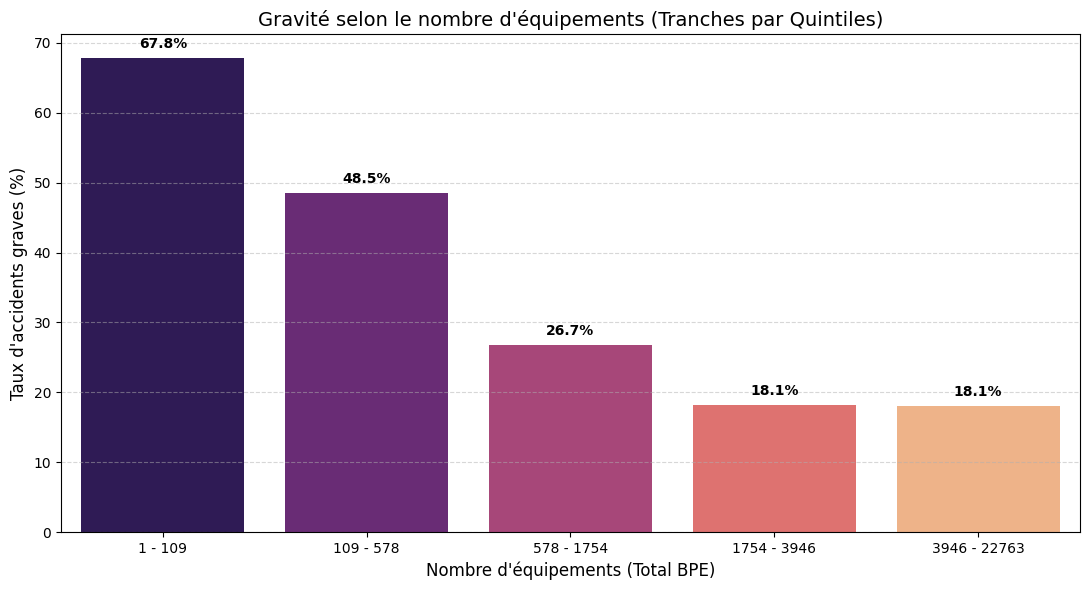

In [12]:
# On crée les quintiles
df['tranche'] = pd.qcut(df['bpe_total_eq'], q=5, duplicates='drop')

# Fonction pour transformer l'intervalle en texte propre "Min - Max"
def format_interval(interval):
    # On arrondit les bornes et on les convertit en entier
    return f"{int(round(interval.left))} - {int(round(interval.right))}"

# Application du formatage
df['tranche_equipements'] = df['tranche'].apply(format_interval)

# Calcul du taux de gravité par tranche
stats_equip = df.groupby(['tranche', 'tranche_equipements'])['is_grave'].mean().reset_index()
stats_equip['is_grave'] = stats_equip['is_grave'] * 100

# Création du Barplot
plt.figure(figsize=(11, 6))
ax = sns.barplot(x='tranche_equipements', y='is_grave', data=stats_equip, palette='magma')

# Ajout des étiquettes de pourcentage
for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontweight='bold', xytext=(0, 5), textcoords='offset points')

plt.title('Gravité selon le nombre d\'équipements (Tranches par Quintiles)', fontsize=14)
plt.xlabel('Nombre d\'équipements (Total BPE)', fontsize=12)
plt.ylabel('Taux d\'accidents graves (%)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

/tmp/ipykernel_429843/1687648287.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='comm_grille_densite', order=order, palette='viridis')


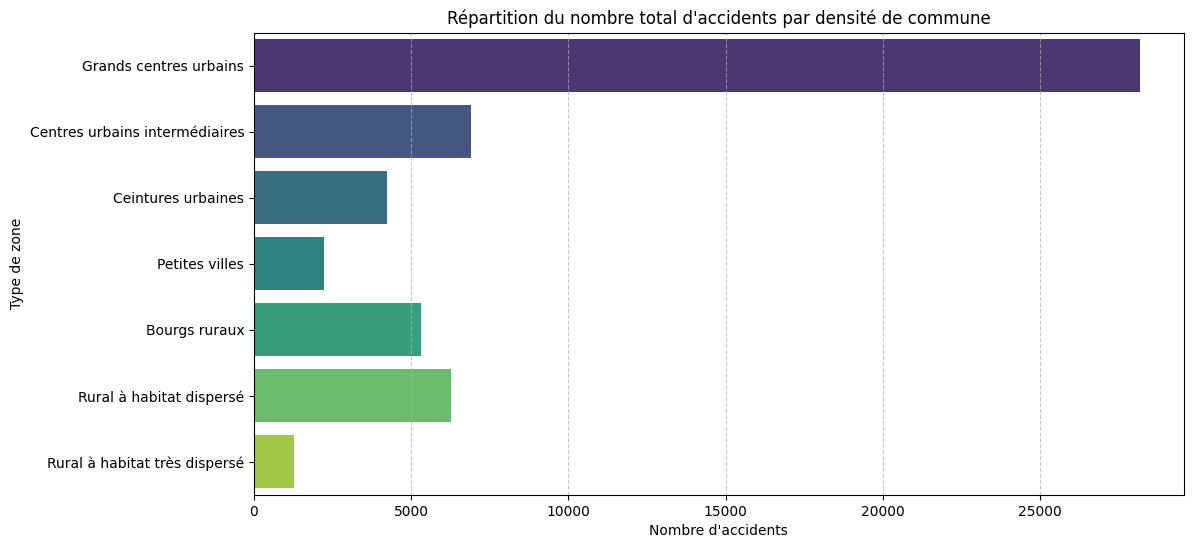

In [13]:
# Calcul du nombre d'accidents par catégorie de densité
order = ['Grands centres urbains', 'Centres urbains intermédiaires', 'Ceintures urbaines',
    'Petites villes', 'Bourgs ruraux', 'Rural à habitat dispersé', 'Rural à habitat très dispersé']

plt.figure(figsize=(12, 6))
sns.countplot(data=df, y='comm_grille_densite', order=order, palette='viridis')

plt.title("Répartition du nombre total d'accidents par densité de commune")
plt.xlabel("Nombre d'accidents")
plt.ylabel("Type de zone")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

On observe que les zones urbaines concentrent le plus grand nombres d'accidents avec plus de 25000 accidents uniquement pour les `Grands centres urbains`.  
On observe egalement une tendance globale à la baisse du nombre d'accidents à mesure que l'on s'éloigne des centres urbains : les `Centres intermédiaires` et les `Ceintures urbaines` suivent, mais avec des volumes nettement inférieurs (autour de 5 000 à 7 000).  
Le milieu `Rural à habitat très dispersé` enregistre le plus faible nombre total d'accidents du jeu de données (avec environ 1000 accidents).


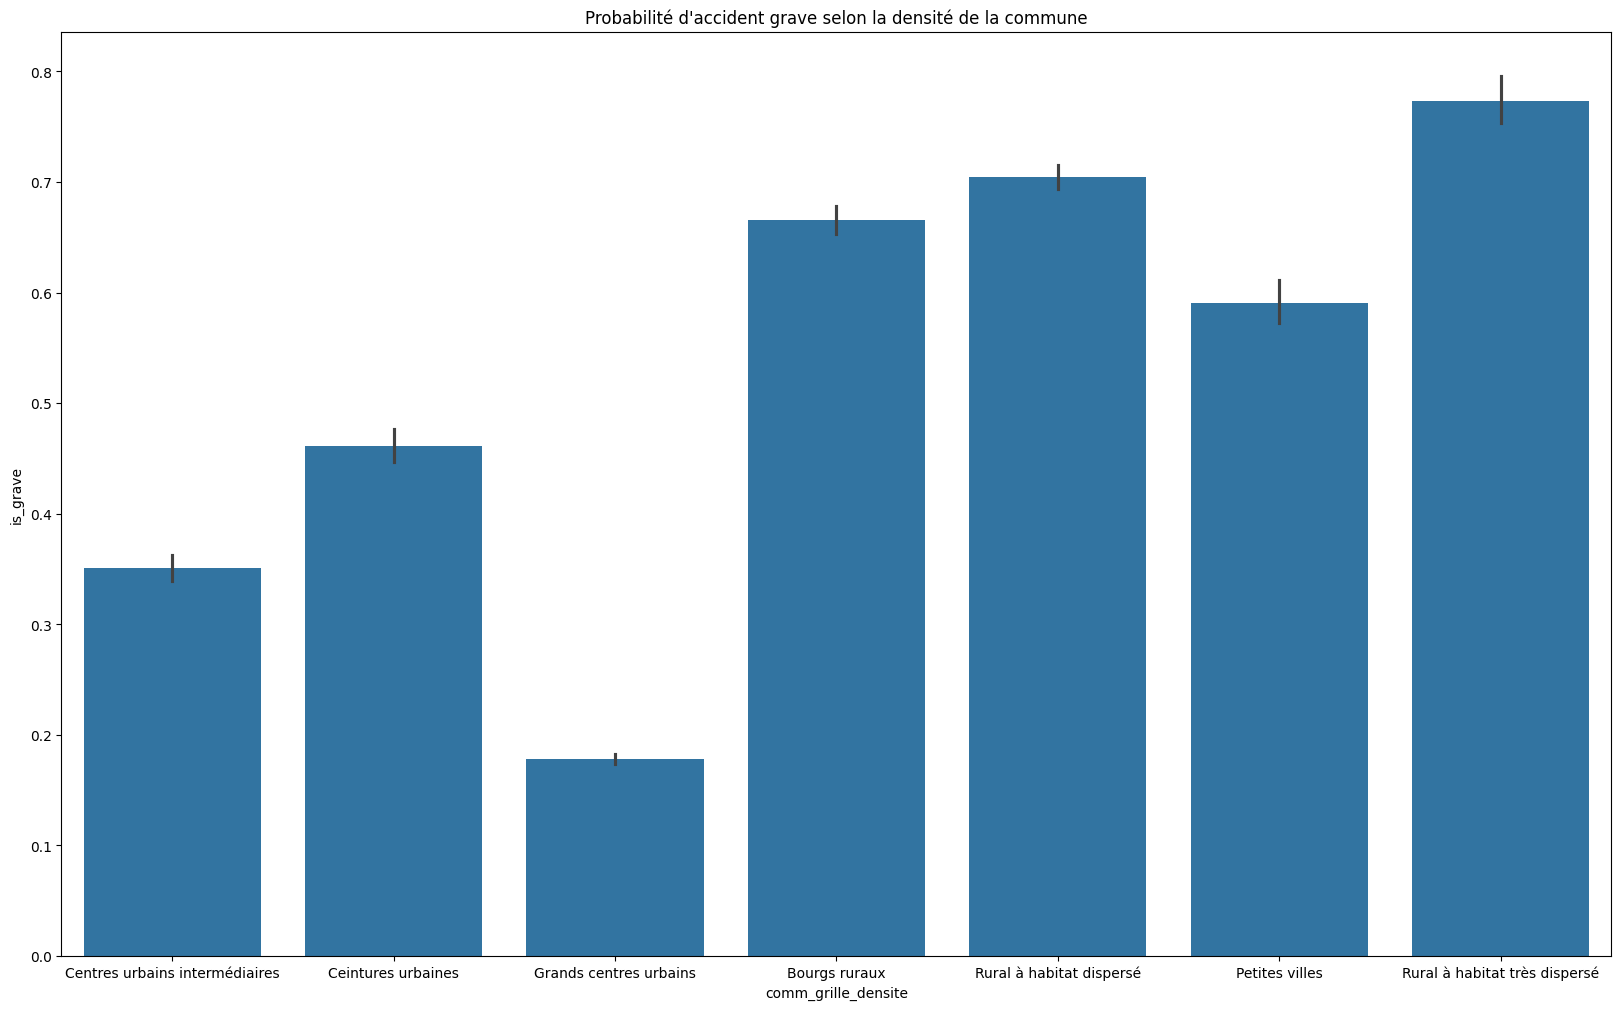

In [14]:
# Taux d'accidents graves par niveau de densité
plt.figure(figsize=(20,12))
sns.barplot(x='comm_grille_densite', y='is_grave', data=df)
plt.title("Probabilité d'accident grave selon la densité de la commune")
plt.show()

Contrairement ce que l'on peut imaginer, ce sont les zones les moins denses qui présentent la probabilité d'accidents graves la plus élevée.  
Les zones `Rural à habitat très dispersé` atteignent un taux de gravité record (proche de 80 %), tandis que les `Grands centres urbains` affichent la probabilité la plus faible (moins de 20 %).

Cette observation s'oppose assez fortement avec le graphique de la répartition du nombre total d'accidents par densité de commune. En ville, il y a énormément d'accidents, mais ils sont majoritairement "légers". Cela peut s'expliquer par une circulation beaucoup plus dense et des chocs à plus petite vitesse que dans des zones rurales. Tandis que en zone rurale, les accidents sont rares en volume, mais lorsqu'ils surviennent, ils sont graves.

##### Mapping et conversion numeriques

In [15]:
# Dictionnaire basé sur le BAAC
mapping_dict = {
    'lum': {1: 'Plein jour', 2: 'Crépuscule ou aube', 3: 'Nuit sans éclairage', 4: 'Nuit éclairée non allumée', 5: 'Nuit éclairée allumée'},
    'agg': {1: 'Hors agglomération', 2: 'En agglomération'},
    'int': {1: 'Hors intersection', 2: 'Intersection en X', 3: 'Intersection en T', 4: 'Intersection en Y', 5: 'Intersection à plus de 4 branches', 6: 'Giratoire', 7: 'Place', 8: 'Passage à niveau', 9: 'Autre intersection'},
    'atm': {-1: 'Non renseigné', 1: 'Normale', 2: 'Pluie légère', 3: 'Pluie forte', 4: 'Neige - grêle', 5: 'Brouillard - fumée', 6: 'Vent fort - tempête', 7: 'Temps éblouissant', 8: 'Temps couvert', 9: 'Autre'},
    'col': {-1: 'Non renseigné', 1: 'Deux véhicules - frontale', 2: 'Deux véhicules - par l’arrière', 3: 'Deux véhicules - par le côté', 4: 'Trois véhicules et plus - en chaîne', 5: 'Trois véhicules et plus - collisions multiples', 6: 'Autre collision', 7: 'Sans collision'},
    'catr': {1: 'Autoroute', 2: 'Route nationale', 3: 'Route Départementale', 4: 'Voie Communale', 5: 'Hors réseau public', 6: 'Parc de stationnement', 7: 'Routes de métropole urbaine', 9: 'Autre'},
    'circ': {-1: 'Non renseigné', 1: 'Sens unique', 2: 'Bidirectionnelle', 3: 'À chaussées séparées', 4: 'Avec voies d’affectation variable'},
    'surf': {-1: 'Non renseigné', 1: 'Normale', 2: 'Mouillée', 3: 'Flaques', 4: 'Inondée', 5: 'Enneigée', 6: 'Boue', 7: 'Verglacée', 8: 'Corps gras', 9:'Autre'},
    'situ': {-1: 'Non renseigné', 0: "Aucun", 1: 'Sur chaussée', 2:"Sur la bande d'arrêt d'urgence", 3: 'Sur accotement', 4: 'Sur trottoir', 5: 'Sur piste cyclable', 6: 'Sur voie ferrée', 8: 'Autre'}
}

In [16]:
# Liste des variables qualitatives à encoder
vars_cat = [
    'lum', 'agg', 'int', 'atm', 'col', 'catr', 'circ', 
    'surf', 'situ','comm_grille_densite'
]

# Liste des variables numériques
vars_num = [
    'bpe_total_eq', 'comm_population', 
    'comm_densite', 'nbv', 'vma', 'n_usagers', 'n_vehicules', 'mois', 'heure'
]


# Nettoyage préalable
df['nbv'] = pd.to_numeric(df['nbv'].replace(['#VALEURMULTI', ' -1'], np.nan), errors='coerce')
df['heure'] = pd.to_numeric(df['hrmn'].str.split(':').str[0], errors='coerce')

# Remplissage des valeurs manquantes
df[vars_num] = df[vars_num].fillna(df[vars_num].median())
for col in vars_cat:
    df[col] = df[col].fillna(df[col].mode()[0])


for col, mapping in mapping_dict.items():
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')
        df[col] = df[col].replace(mapping)


# Application du One-Hot Encoding
X = pd.get_dummies(df[vars_cat + vars_num], columns=vars_cat, drop_first=True)
print(f"Dimensions du dataset après encodage : {X.shape}")

# Sélection des features One-hot interessantes
threshold = 0.05
cols_to_keep = [col for col in X.columns if X[col].mean() > threshold]
X = X[cols_to_keep]
print(f"Dimensions du dataset après encodage et sélection : {X.shape}")



y = df['is_grave']

features = X.columns.tolist()

Dimensions du dataset après encodage : (54402, 70)
Dimensions du dataset après encodage et sélection : (54402, 37)


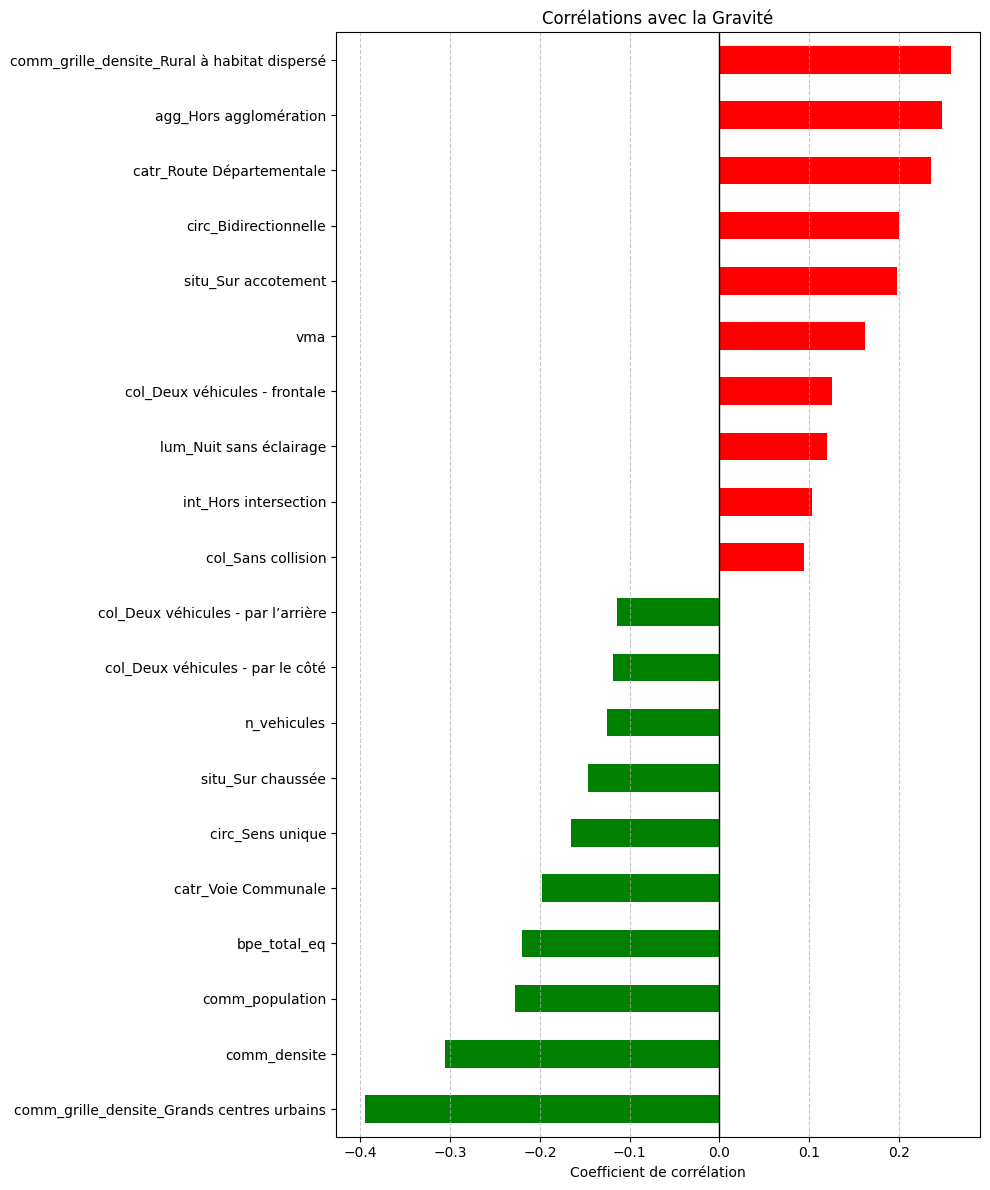

In [17]:
# Ajout la cible au DataFrame final pour calculer la corrélation
X_with_target = X.copy()
X_with_target['is_grave'] = y

# Calcul des corrélations uniquement avec la cible
correlations = X_with_target.corr()['is_grave'].drop('is_grave').sort_values()

# Affichage des 20 plus fortes corrélations (positives et négatives)
top_correlations = pd.concat([correlations.head(10), correlations.tail(10)])

plt.figure(figsize=(10, 12))
top_correlations.plot(kind='barh', color=['red' if x > 0 else 'green' for x in top_correlations])
plt.title("Corrélations avec la Gravité")
plt.xlabel("Coefficient de corrélation")
plt.axvline(x=0, color='black', linestyle='-', linewidth=1)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

En accord avec ce que nous avons pu constater précédemment, on observe une correlation négative entre les `Grands centres urbains` et la gravité des accidents. Et inversement, une corrélation positive entre `Rural à habitations dispersés` et la gravité.  
Ce graphique nous permet aussi de s'intéresser au corrélation entre la gravité les autres variables. On observe par exemple, une corrélation positive avec `vma`(la vitesse), ce qui semble assez logique.

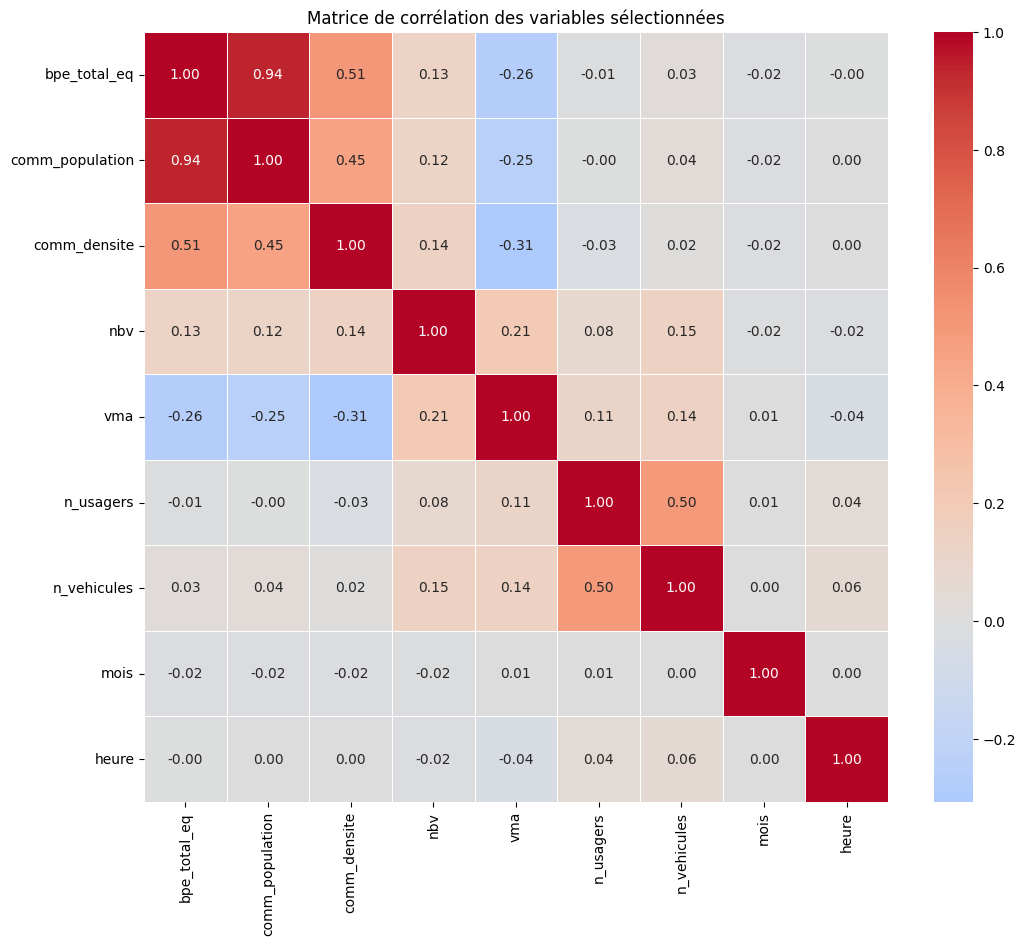

In [18]:
# On calcule la matrice de corrélation pour les variables quantitatives
plt.figure(figsize=(12, 10))
correlation_matrix = df[vars_num].corr()

# Création de la Heatmap
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', 
            linewidths=0.5, center=0)

plt.title("Matrice de corrélation des variables sélectionnées")
plt.show()

On observe une corrélation positive quasiment parfaite entre `comm_population` et `bpe_total_eq`.  
Afin d'isoler au mieux l'impact des infrastructures et de répondre précisément à notre problématique, nous avons choisi de retirer la variable comm_population du modèle. Étant corrélée à 95 % avec le niveau d'équipements (`bpe_total_eq`), elle créait une redondance. Ce choix permet de mettre en lumière l'influence propre des services et de la densité sur la gravité des accidents.

In [19]:
X = X.drop(columns=['comm_population'])
features.remove('comm_population')
vars_num.remove('comm_population')

In [20]:
# Split Train/Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

### Random Forest

In [21]:
# Modèle Random Forest
model_forest = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
model_forest.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [22]:
# Importance des variables
importances = pd.Series(model_forest.feature_importances_, index=features).sort_values(ascending=False)

# Conversion en pourcentage et arrondi à 2 décimales
importances_pourcent = (importances * 100).round(2)

print("Importance des variables (en %) :")
print(importances_pourcent.astype(str) + ' %')

Importance des variables (en %) :
comm_densite                                          21.02 %
bpe_total_eq                                          15.74 %
heure                                                  9.37 %
mois                                                   8.28 %
comm_grille_densite_Grands centres urbains             4.55 %
vma                                                     4.5 %
n_usagers                                              3.73 %
nbv                                                    3.47 %
n_vehicules                                             2.0 %
agg_Hors agglomération                                 1.96 %
catr_Route Départementale                              1.56 %
int_Hors intersection                                  1.54 %
circ_Bidirectionnelle                                  1.52 %
lum_Plein jour                                         1.33 %
catr_Voie Communale                                    1.26 %
situ_Sur chaussée                   

On observe que le facteur "territoriel" est celui qui est le plus important. 
Les variables `comm_densite`, `bpe_total_eq`(total des équipements) expliquent à elles seules uen grande partie des prédictions du modèle.

Le facteur "temporel" avec les variables `heure` et `mois` ont également une importance et laisse suggérer, comme on peut naturellement le penser, que les conditions cycliques ont une influence (par ex. fatigue nocturne pour l'heure, ou conditions climatiques pour le mois)

On peut egalement constater que les variables portant sur la vitesse et le nombre de voies (`vma`/`nbv`) sont assez peu significatives car ces variables sont secondaires par rapport au contexte géographique. La vitesse est souvent une conséquence de la zone (on roule vite parce qu'on est en zone peu dense), et c'est donc la zone qui capte le plus d'importance.

Egalement, de manière assez surprenante, on observe que des variables pouvant être jugées critiques comme une météo pluvieuse(`atm_Pluie légère`) ou la luminosité (`lum_Nuit sans éclairage`) ont un impact très faible sur la prédiction finale.  
Le modèle peut peut-être"estimer" que si l'on connaît déjà la densité de la zone et le nombre d'equipements, savoir s'il pleuvait apporte peu d'information supplémentaire pour déterminer la gravité.

--- Rapport de Classification ---
              precision    recall  f1-score   support

           0       0.78      0.85      0.81      6949
           1       0.69      0.58      0.63      3932

    accuracy                           0.75     10881
   macro avg       0.73      0.72      0.72     10881
weighted avg       0.75      0.75      0.75     10881



<Figure size 800x600 with 0 Axes>

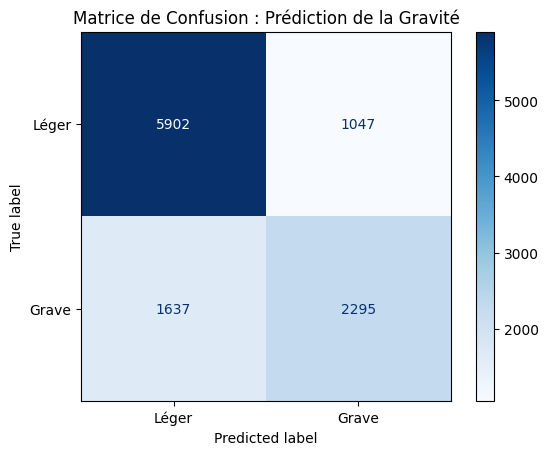

In [23]:
# Prédictions sur le jeu de test
y_pred = model_forest.predict(X_test)

# Affichage du rapport de performance
print("--- Rapport de Classification ---")
print(classification_report(y_test, y_pred))

# Affichage de la Matrice de Confusion
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Léger', 'Grave'])
disp.plot(cmap='Blues', values_format='d')
plt.title("Matrice de Confusion : Prédiction de la Gravité")
plt.show()

L'analyse des performances de notre modèle Random Forest révèle une capacité de prédiction solide mais nuancée. Avec une précision globale de 76 %, le modèle surpasse un choix aléatoire. On constate de très bonnes performances principalement dans l'identification des accidents légers (F1-score de 0,82), laissant penser que les environnements urbains denses et dotés d'un haut niveau de services créent une caracteristique de sécurité très reconnaissable : dans ces zones, lla densité est plus forte entrainant une vitesse moins élevée, ce qui permet au modèle de classer ces événements avec une grande fiabilité (rappel de 85 %).  

Concernant la classe des accidents graves, le modèle atteint une précision de 69 % pour un rappel de 58 %. Ce résultat indique que si les variables territoriales (faible densité, peu d'equipements) sont des indicateurs de risque fiables, elles ne suffisent pas à capturer l'intégralité de la gravité. Environ 40 % des accidents graves échappent à la détection, on peut donc penser que la gravité d'un accident dépend également de facteurs non présents dans les variables selectionnés. 

In [24]:
# Préparation des données normalisées (pour la Régression Logistique)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Définition des modèles

model_log = LogisticRegression(class_weight='balanced')
models = {
    "Regression Logistique": model_log,
    "Random Forest": model_forest,
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=42),
    # "SVM": SVC(kernel='linear', class_weight='balanced', probability=True, random_state=42),
    #"Naive Bayes": GaussianNB(),
    #"Neural Net": MLPClassifier(hidden_layer_sizes=(50, 20), max_iter=500, activation='relu', solver='adam', random_state=42) 
}

In [25]:
# Initialisation d'un dictionnaire pour stocker toutes les métriques
metrics = []

for name, mdl in models.items():
   # Modèles sensibles à l'échelle
    if name in ["Regression Logistique", "KNN", "SVM", "Naive Bayes", "Neural Net"]:
        X_tr, X_ts = X_train_scaled, X_test_scaled
    # Modèles basés sur les arbres
    else:
        X_tr, X_ts = X_train, X_test
    
    # Entraînement et prédiction
    mdl.fit(X_tr, y_train)
    preds = mdl.predict(X_ts)
    
   # Calcul des métriques pour les deux classes (0: Léger, 1: Grave)
    # average=None permet d'obtenir les scores pour chaque classe séparément
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, preds, average=None)
    acc = accuracy_score(y_test, preds)
    
    # On ajoute les résultats au tableau
    metrics.append({
        "Modèle": name,
        "Accuracy Globale": acc,
        "Précision (Léger)": precision[0],
        "Rappel (Léger)": recall[0],
        "F1-Score (Léger)": f1[0],
        "Précision (Grave)": precision[1],
        "Rappel (Grave)": recall[1],
        "F1-Score (Grave)": f1[1]
    })

# 2. Création et mise en forme du DataFrame
df_final = pd.DataFrame(metrics).set_index("Modèle")

print("Comparaison des performances des modèles (%)")
display(df_final.round(4) * 100)

Comparaison des performances des modèles (%)


,Accuracy Globale,Précision (Léger),Rappel (Léger),F1-Score (Léger),Précision (Grave),Rappel (Grave),F1-Score (Grave)
Modèle,,,,,,,
Regression Logistique,74.08,82.31,75.68,78.86,62.38,71.26,66.52
Random Forest,75.33,78.29,84.93,81.47,68.67,58.37,63.10
Gradient Boosting,75.96,79.17,84.62,81.80,69.05,60.66,64.58
KNN,71.76,76.22,81.06,78.57,62.30,55.32,58.60
AdaBoost,75.21,78.69,83.91,81.22,67.79,59.84,63.57


De manière globale, on peut constater que tout nos modèles ont des performances assez similaires.
Le modèle de `Regression Logistique` est le seul à avoir des performances qui diffère légèrement des autres modèles.  


#### Interprétation des résultats
- Les modèles arbres/boosting (Random Forest, Gradient Boosting, AdaBoost) obtiennent ~0,75 d’accuracy et un F1 « Grave » autour de 0,63–0,65. Ils exploitent bien les non-linéarités des variables territoriales (densité, équipements) : les accidents « légers » en zone urbaine dense sont bien identifiés, mais la classe « grave » reste plus difficile à isoler (signal plus rare, facteurs non observés comme vitesse réelle, état de la route).
- La régression logistique (balanced) a une accuracy plus basse (~0,74) mais un F1 « Grave » légèrement meilleur (~0,66). En pondérant la classe minoritaire, elle favorise la détection des accidents graves au détriment de l’accuracy globale.
- L’arbre de décision (profondeur 3) est explicable mais moins performant (acc ~0,71) : il tronque la complexité des interactions (densité × vitesse × heure).
- KNN est le moins performant (acc ~0,72, F1 « Grave » ~0,59) car la distance est peu informative en haute dimension (nombreux one-hot) et les échelles varient.

Pourquoi ces performances :
- **Données** : la gravité est pilotée par le contexte territorial (densité/équipements) et des facteurs ponctuels (vitesse effective, infrastructure fine) non mesurés. Les modèles captent surtout la composante territoriale, donc prédisent bien les cas « légers » en urbain, moins bien les graves.
- **Déséquilibre modéré** : la classe grave (~35 %) est moins fréquente ; les modèles optimisent l’accuracy et pénalisent la détection de cette classe, d’où l’intérêt du class_weight (logistique) pour relever le F1 grave.
- **Bruit et agrégations** : certaines variables sont agrégées ou proxies (commune vs lieu exact, heure grossière). Le signal est dilué, limitant la marge de progression sur la classe grave.
- **Non-linéarités / interactions** : les méthodes arborescentes en profitent (meilleure accuracy), alors que la logistique reste linéaire (meilleure sensibilité à la classe grave grâce au pondération).
En résumé : le contexte territorial domine le pouvoir prédictif, ce qui explique la bonne prédiction des accidents légers en zone dense. Les accidents graves, plus liés à des facteurs locaux (vitesse, isolement, infrastructure fine), restent partiellement capturés, d’où des scores F1 modestes malgré un class_weight.```



#### Analyse des coefficients des variables (Regression Logistique)

/tmp/ipykernel_429843/1847777737.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_coeffs_sub['Odds_Ratio'] = np.exp(df_coeffs_sub['Coefficient'])


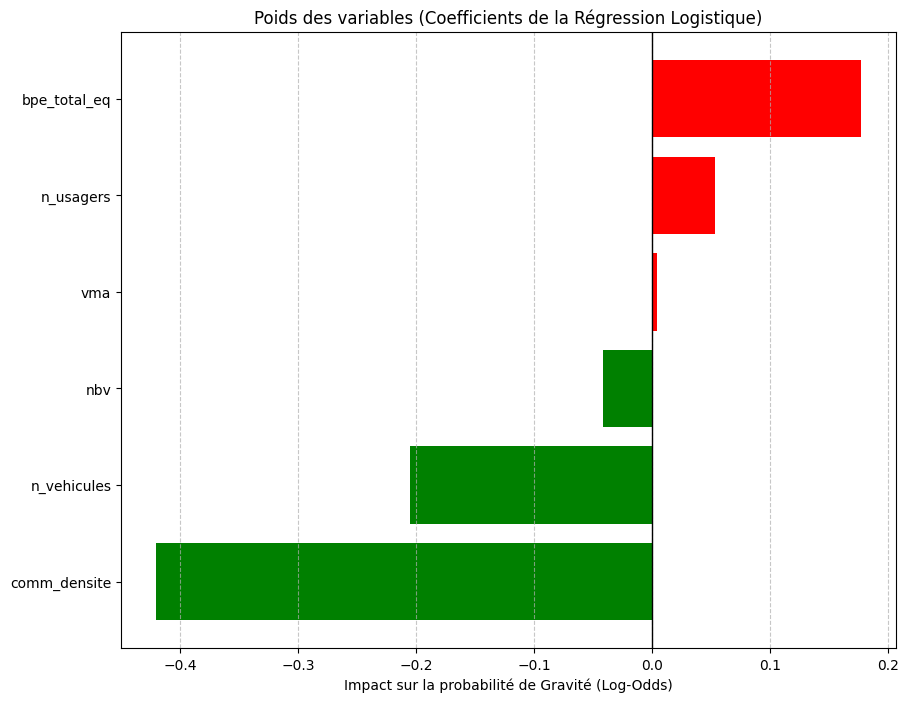

In [26]:
coefficients = model_log.coef_[0]
feature_names = X_train.columns

# Création d'un DataFrame pour manipuler les données facilement
df_coeffs = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

# Filtrer pour ne garder que les variables quantitatives d'intérêt
vars_territoire = ['bpe_total_eq', 'comm_densite', 'nbv', 'vma', 'n_usagers', 'n_vehicules']
df_coeffs_sub = df_coeffs[df_coeffs['Feature'].isin(vars_territoire)]

# Calcul de l'exponentielle des coefficients pour obtenir les "Odds Ratios"
df_coeffs_sub['Odds_Ratio'] = np.exp(df_coeffs_sub['Coefficient'])
df_coeffs_sub = df_coeffs_sub.sort_values(by='Coefficient', ascending=True)

plt.figure(figsize=(10, 8))
colors = ['red' if x > 0 else 'green' for x in df_coeffs_sub['Coefficient']]
plt.barh(df_coeffs_sub['Feature'], df_coeffs_sub['Coefficient'], color=colors)
plt.axvline(x=0, color='black', linestyle='-', linewidth=1)
plt.title("Poids des variables (Coefficients de la Régression Logistique)")
plt.xlabel("Impact sur la probabilité de Gravité (Log-Odds)")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

#### Arbre de décision

Nous allons maintenant faire un arbre de décision dans l'optique de pouvoir avoir une meilleur explicabilité concernant nos variables

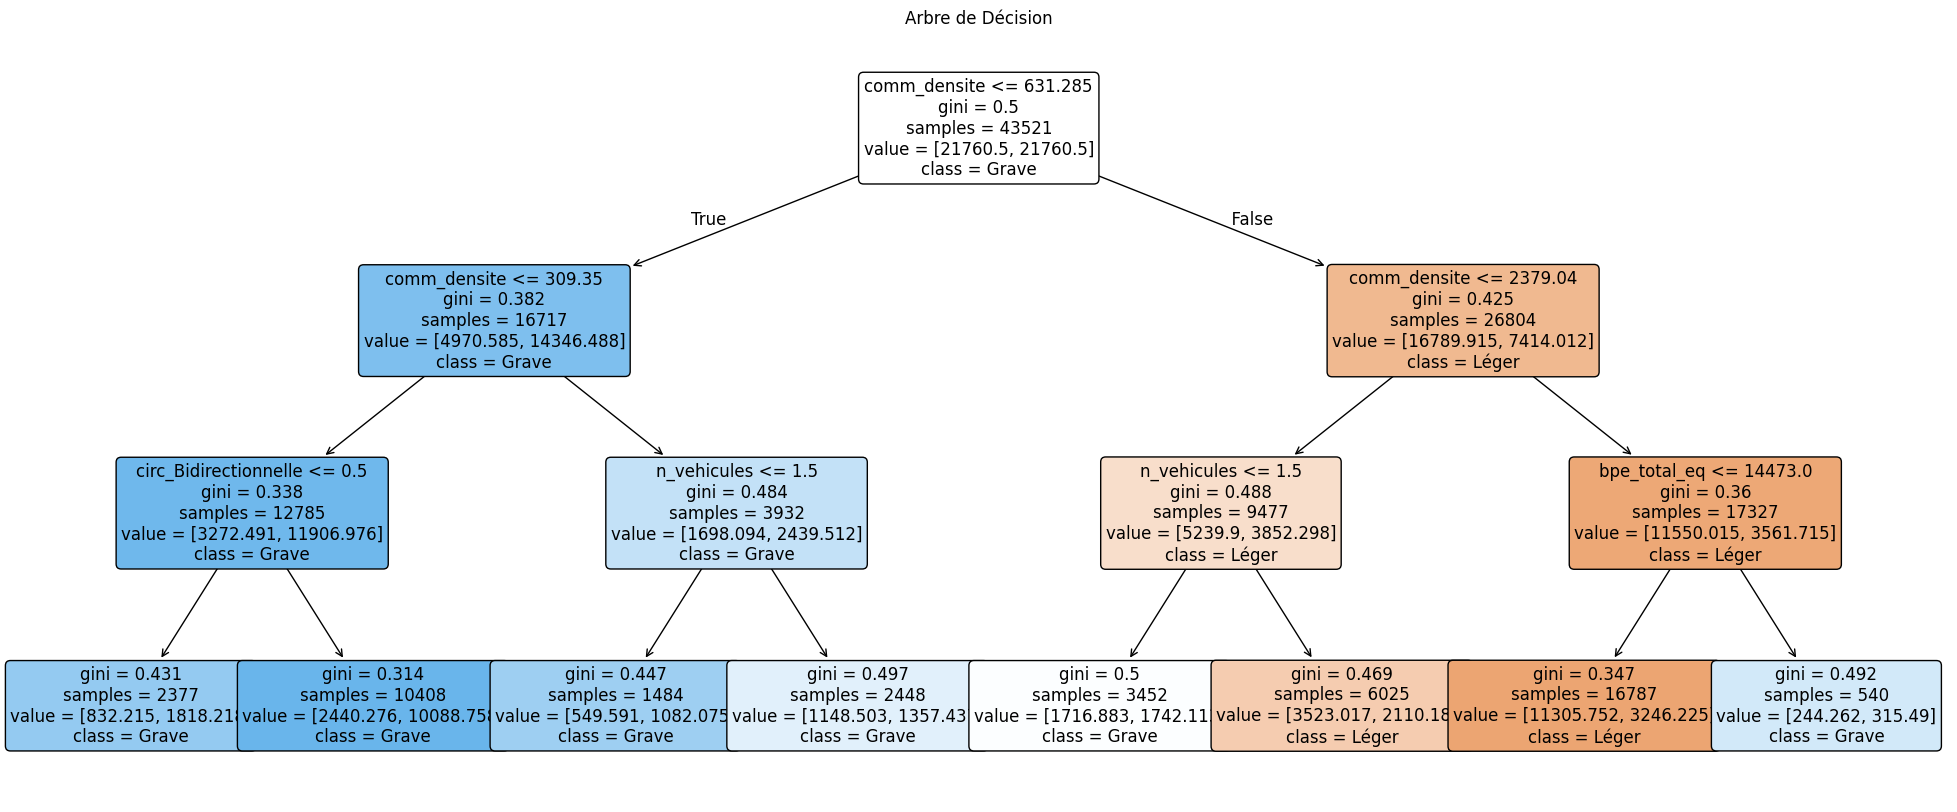

In [27]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Arbre simple pour l'explicabilité (profondeur max de 3 pour rester lisible)
model_tree = DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=42)
model_tree.fit(X_train, y_train)

# Visualisation
plt.figure(figsize=(25, 10))
plot_tree(model_tree, 
          feature_names=X_train.columns, 
          class_names=['Léger', 'Grave'], 
          filled=True, 
          rounded=True, 
          fontsize=12)
plt.title("Arbre de Décision")
plt.show()

On constate, à la racine de notre arbre, que la "prédiction" est realisé à partir de la variable `comm_densité`, qui d'après les autres modèles (Regression Logistique, Random Forest) étaient également la variable la plus influente.  
Ici, on remarque que la séparation aau niveau de la racine se fait pour `comm_densité <= 631,285`. On peut donc considérer que notre modèle considère cette valeur comme un seuil de danger. On voit que pour le modèle, tout accident ayant lieu dans une zone où la densité est inferieur à ce seuil, est un accident grave. Cet lien semble être un peu grotesque.


Comparaison des performances des modèles (%)


,Accuracy Globale,Précision (Léger),Rappel (Léger),F1-Score (Léger),Précision (Grave),Rappel (Grave),F1-Score (Grave)
Modèle,,,,,,,
Regression Logistique,74.08,82.31,75.68,78.86,62.38,71.26,66.52
Random Forest,75.33,78.29,84.93,81.47,68.67,58.37,63.10
Gradient Boosting,75.96,79.17,84.62,81.80,69.05,60.66,64.58
KNN,71.76,76.22,81.06,78.57,62.30,55.32,58.60
AdaBoost,75.21,78.69,83.91,81.22,67.79,59.84,63.57
Arbre de Décision,71.33,83.63,68.51,75.32,57.83,76.30,65.79


<Figure size 800x600 with 0 Axes>

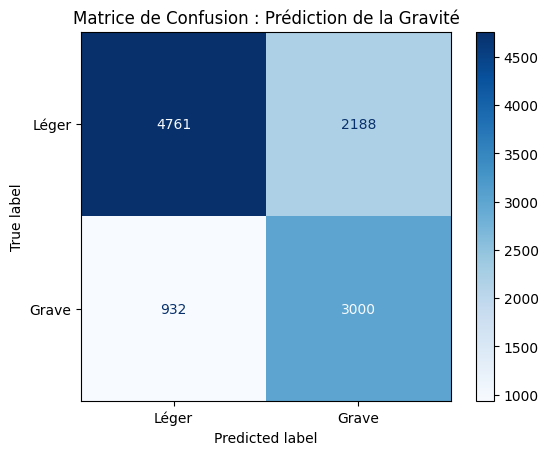

In [28]:
# Prédictions sur le jeu de test
y_pred = model_tree.predict(X_test)

precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred=y_pred, average=None)
acc = accuracy_score(y_test, y_pred)

metrics = [m for m in metrics if m["Modèle"] != "Arbre de Décision"]

# On ajoute les résultats au tableau
metrics.append({
    "Modèle": "Arbre de Décision",
    "Accuracy Globale": acc,
    "Précision (Léger)": precision[0],
    "Rappel (Léger)": recall[0],
    "F1-Score (Léger)": f1[0],
    "Précision (Grave)": precision[1],
    "Rappel (Grave)": recall[1],
    "F1-Score (Grave)": f1[1]
})

# 2. Création et mise en forme du DataFrame
df_final = pd.DataFrame(metrics).set_index("Modèle")

print("Comparaison des performances des modèles (%)")
display(df_final.round(4) * 100)

# Affichage de la Matrice de Confusion
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Léger', 'Grave'])
disp.plot(cmap='Blues', values_format='d')
plt.title("Matrice de Confusion : Prédiction de la Gravité")
plt.show()

Avec notre matrice de confusion, on peut surtout remarquer que notre arbre de décision a tendance à classer comme `Grave`, des accidents qui sont en réalité légers. On a donc une sur-prédiction de la classe `Grave` (2188 faux positifs),c'est la conséquence directe du fait que, dès que la densité est inférieure au seuil, l'arbre "bascule" par défaut vers la classe `Grave`.  
Par conséquent, on remarque également que notre modèle a très peu de faux négatifs (Accidents `Grave` classés comme `Légers`)